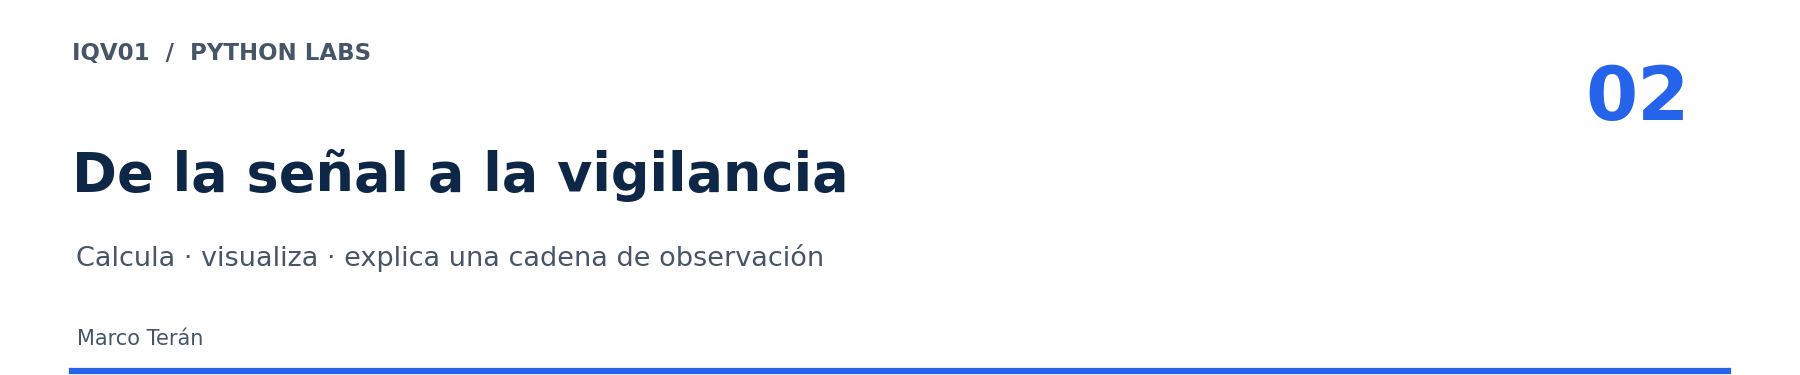

**Tu ruta en cada sección:** problema físico → intuición → modelo → cálculo en Python → observación → interpretación → experimento.

### Antes de empezar

- **Requisito:** haber completado el Laboratorio 01. Cuando aparezca una herramienta de Python que allí no se vio, un recuadro **Python nuevo** la explica justo antes de usarla.
- **Cómo avanzar:** ejecuta las celdas de arriba hacia abajo con ▶ o `Shift + Enter`. La primera celda de código define funciones que usan todas las demás: si reinicias el kernel, vuelve a ejecutarla.
- **Ejercicios:** cambia `None` por tu expresión. La función `mostrar()` compara tu resultado con la referencia y escribe ✓ o «revisa». Conserva las unidades.
- En Colab, guarda una copia en Drive antes de trabajar.

Una torre recibe señales; un sistema de vigilancia produce observaciones con **tiempo, origen y calidad**.
Una potencia alta o un mensaje recibido no garantizan una posición correcta.

Trabajaremos con modelos y datos sintéticos. Cada resultado debe incluir su unidad y sus supuestos.
Usamos $c=3.00\times10^8$ m/s como aproximación didáctica.

Fenómeno: lo que ocurre; señal: magnitud observable; dato: representación registrada; información: interpretación con contexto. No son sinónimos.

### Qué aprenderás

Al terminar podrás calcular e interpretar, con Python y con unidades explícitas:

1. potencias en W, dBm y dB, y por qué la ingeniería RF suma decibelios;
2. señales en el tiempo y en la frecuencia, pulsos y ruido;
3. un enlace de radio en un solo sentido (potencia ∝ 1/R²) frente a un eco radar de ida y vuelta (potencia ∝ 1/R⁴);
4. cómo un arreglo de antenas forma y orienta un haz;
5. qué mide y qué recibe cada sistema: PSR, SSR, Mode S, ADS-B y MLAT;
6. qué ocurre al digitalizar una señal y al transportar datos por una red.

| § | Tema | Python que practicarás |
|---|---|---|
| 1 | Unidades y decibelios | Funciones, `np.log10`, notación científica |
| 2 | Alimentación | Fórmulas con variables y unidades |
| 3 | Señales, pulsos y ruido | `np.arange`, FFT, dos gráficos en una figura |
| 4 | Propagación de un enlace | Presupuesto en dB con variables con nombre |
| 5 | Antenas y haz | Números complejos, arrays 2D, controles interactivos |
| 6 | Ecuación radar | Valores por defecto, escala logarítmica |
| 7 | Del tiempo a la observación | Conversión de tiempo a distancia |
| 8 | Información digital | `np.where`, binario y hexadecimal |
| 9 | Red | Latencia, jitter y disponibilidad |
| Misión | Doce cálculos de diagnóstico | Todo lo anterior |

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

C = 3.00e8  # m/s
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "axes.titleweight": "bold"})

def w_a_dbm(potencia_w):
    return 10 * np.log10(potencia_w / 1e-3)

def db_a_factor(valor_db):
    return 10 ** (valor_db / 10)

def mostrar(respuestas, esperado, etiquetas):
    """Comprueba varios números sin detener los ejercicios pendientes."""
    for nombre, valor, ref in zip(etiquetas, respuestas, esperado):
        if valor is None:
            print(f"{nombre}: pendiente")
        else:
            correcto = np.isclose(valor, ref, rtol=1e-4, atol=1e-9)
            print(f"{nombre}: {valor:.6g} | {'✓' if correcto else 'revisa'}")

**Qué hace la celda anterior.** Prepara lo que usarás después; no produce salida visible.

- Importa `math`, NumPy y Matplotlib, como en el Laboratorio 01. `display` muestra objetos como tablas o controles.
- `C = 3.00e8` guarda la velocidad de la luz en m/s. Escribirla en mayúsculas es una convención para **constantes**: valores que no deben cambiar.
- `plt.rcParams.update({...})` fija un estilo común para todos los gráficos.
- `w_a_dbm` convierte vatios a dBm y `db_a_factor` convierte dB a un factor lineal. Se explican en §1 y las usarás en casi todas las secciones.
- `mostrar` revisa los ejercicios de la misión. Usa `zip`, que recorre varias listas **en paralelo** (nombre, valor y referencia de cada resultado), y `np.isclose`, que acepta diferencias diminutas de redondeo. No necesitas modificarla.

> **Python nuevo · diccionarios.** `{"clave": valor, ...}` es un **diccionario**: asocia nombres con valores. Aquí solo configura el estilo de los gráficos.

## 1 · Unidades antes que fórmulas

**El problema.** En vigilancia conviven números muy distintos: un radar emite pulsos de decenas de kW y recibe ecos de una décima de picovatio. Antes de cualquier fórmula hay que escribir bien las unidades.

**Prefijos y notación científica.** Convierte siempre a unidades SI (m, s, W, Hz) antes de calcular.

| Prefijo | Factor | Ejemplo en SI |
|---|---:|---|
| p, n, µ, m | $10^{-12},10^{-9},10^{-6},10^{-3}$ | 100 ns = `100e-9` s |
| k, M, G | $10^3,10^6,10^9$ | 1090 MHz = `1090e6` Hz |

Una sección de 2.5 mm² vale `2.5e-6` m², porque se eleva al cuadrado el factor de longitud. Un byte contiene 8 bits.

**Decibelios: multiplicar sumando.** El decibelio expresa una **relación** entre dos potencias:
$$x_{dB}=10\log_{10}\left(\frac{P_2}{P_1}\right).$$
Duplicar una potencia equivale a +3.01 dB; multiplicarla por 10, a +10 dB; dividirla por 1000, a −30 dB. Como el logaritmo convierte productos en sumas, una cadena de ganancias y pérdidas se calcula **sumando y restando dB**.

- **dB**: relación entre potencias, sin unidad.
- **dBm**: potencia absoluta referida a 1 mW, $P_{dBm}=10\log_{10}(P/1\,\text{mW})$. Así, 1 mW = 0 dBm y 1 W = 30 dBm.
- **dBW**: potencia referida a 1 W, de modo que $P_{dBW}=P_{dBm}-30$.
- De vuelta a escala lineal: $P=1\,\text{mW}\cdot10^{P_{dBm}/10}$.

**Error frecuente:** sumar potencias en dBm. 0 dBm más 0 dBm son 1 mW + 1 mW = 2 mW ≈ 3.01 dBm, no 0 dBm. Convierte a W, suma y vuelve a dBm.

**Predice** la salida de cada línea; luego ejecuta.

In [2]:
potencia_w = 0.1
print(f"{potencia_w} W = {w_a_dbm(potencia_w):.1f} dBm")
print(f"Doble potencia: {10*np.log10(2):.2f} dB")
print(f"30 dBm = {1e-3 * db_a_factor(30):.1f} W")
print(f"30 dBm = {30-30} dBW")

0.1 W = 20.0 dBm
Doble potencia: 3.01 dB
30 dBm = 1.0 W
30 dBm = 0 dBW


**Lee el código.** `w_a_dbm(0.1)` aplica $10\log_{10}(0.1/10^{-3})=10\log_{10}(100)=20$ dBm. `db_a_factor(30)` aplica $10^{30/10}=1000$; multiplicado por 1 mW da 1 W. La última línea usa que dBW = dBm − 30.

**Experimenta:** en una celda nueva calcula `w_a_dbm(50e3)` (un pico de 50 kW) y `w_a_dbm(1e-13)` (un eco débil). ¿Cuántos dB los separan? Ese rango enorme es la razón por la que la ingeniería RF trabaja en decibelios.

## 2 · Alimentación: fuente → camino → carga

**El problema.** Un radar o una estación ADS-B dejan de vigilar si su alimentación falla o llega degradada. Este bloque calcula cuánto se pierde en un cable y cuánto dura una batería.

El voltaje es una diferencia entre dos puntos. La corriente es carga por tiempo: $I=\Delta Q/\Delta t$.
Para una resistencia óhmica: $V=IR$. La potencia es $P=VI$; la energía, $E=Pt$.

Un cable tiene $R=\rho L/A$, con ρ la resistividad del material (Ω·m), L la longitud (m) y A la sección (m²). **L incluye ida y retorno**.
Con corriente constante: caída $IR$, pérdida $I^2R$. Una fuente correcta en vacío no prueba la tensión bajo carga.

In [3]:
rho = 1.68e-8  # ohm·m, valor supuesto para el ejemplo
longitud_total_m = 30
seccion_m2 = 2.5e-6
corriente_a = 3
r_cable = rho * longitud_total_m / seccion_m2
print(f"Cable: {r_cable:.4f} Ω")
print(f"Caída: {corriente_a*r_cable:.4f} V")
print(f"Pérdida: {corriente_a**2*r_cable:.4f} W")

Cable: 0.2016 Ω
Caída: 0.6048 V
Pérdida: 1.8144 W


**Interpreta.** Una caída de 0.6 V sobre una fuente de 48 V es 1.3%: pequeña, pero los 1.8 W perdidos se convierten en calor en el cable. **Experimenta:** cambia `corriente_a` a 6. La caída se duplica y la pérdida se multiplica por 4, porque depende de $I^2$.

Una batería de 24 V y 100 Ah almacena nominalmente 2400 Wh.
Si usamos 50% de esa energía y la eficiencia es 85%, quedan 1020 Wh útiles.
A 120 W constantes dura 8.5 h. Este modelo omite envejecimiento y variación de carga.

In [4]:
energia_util_wh = 24 * 100 * 0.50 * 0.85
print(f"Autonomía ideal ajustada: {energia_util_wh / 120:.1f} h")

Autonomía ideal ajustada: 8.5 h


## 3 · Señales: lo que cambia en el tiempo

**El problema.** Todo lo que observa un sensor es una señal: una magnitud que cambia en el tiempo. Un radar emite pulsos; una emisora, una onda continua modulada. Necesitamos describirlas en el tiempo y en la frecuencia.

Un seno sigue $x(t)=A\sin(2\pi ft+\phi)$: amplitud A (V), frecuencia f (Hz), tiempo t (s) y fase φ (rad).
$T=1/f$ es el período y $\omega=2\pi f$ la frecuencia angular. Para un seno puro: $V_{rms}=V_p/\sqrt2$; $V_{pp}=2V_p$.
DC/AC describe variación temporal; analógico/digital describe representación.

La **FFT** (transformada rápida de Fourier) descompone una señal muestreada en sus componentes de frecuencia, como un prisma separa los colores de la luz. Aquí graficamos la **amplitud de un seno sintético**, con muestreo uniforme, número entero de ciclos y sin calibración a dBm.

La fase positiva adelanta este seno: un desplazamiento de 90° a 50 Hz equivale a 5 ms. La fase temporal de una señal no es el ángulo espacial de una antena. Ancho de banda puede referirse a contenido de señal, paso de un sistema o banda equivalente de ruido: declara cuál usas.

> **Python nuevo · en la celda siguiente**
> - `t = np.arange(2000) / fs` crea 2000 instantes separados $1/f_s$ = 0.5 ms: un segundo de **muestras**.
> - `np.fft.rfft(x)` calcula la FFT y `np.fft.rfftfreq` da la frecuencia de cada resultado. `np.abs` toma el módulo, porque la FFT produce números complejos.
> - `amplitud[1:-1] *= 2` multiplica por 2 todos los elementos excepto el primero y el último. `a *= 2` abrevia `a = a * 2`.
> - `fig, ax = plt.subplots(1, 2)` crea **dos** gráficos lado a lado: `ax[0]` es el izquierdo y `ax[1]` el derecho. `ax[0].set(...)` fija varias etiquetas a la vez.
> - `t[:120]*1e3` toma las 120 primeras muestras y convierte segundos a milisegundos.

RMS: 1.414 V


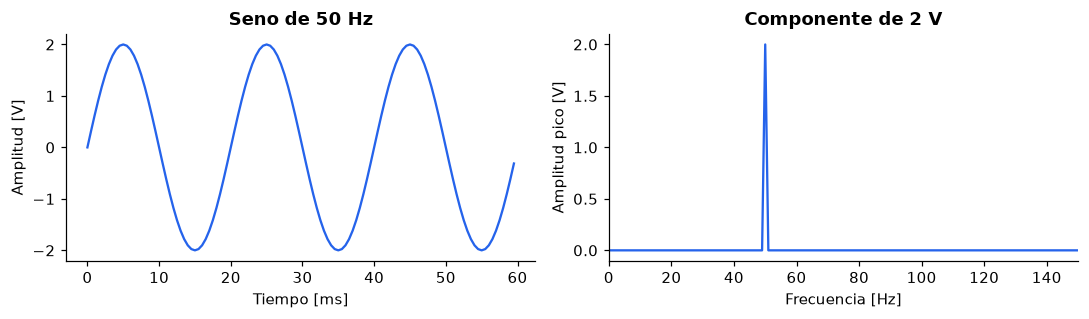

In [5]:
fs = 2000  # Hz
t = np.arange(2000) / fs
x = 2 * np.sin(2*np.pi*50*t)
frecuencias = np.fft.rfftfreq(len(x), 1/fs)
amplitud = np.abs(np.fft.rfft(x)) / len(x)
amplitud[1:-1] *= 2  # espectro unilateral; DC y Nyquist no se duplican
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(t[:120]*1e3, x[:120], color="#2563EB")
ax[0].set(xlabel="Tiempo [ms]", ylabel="Amplitud [V]", title="Seno de 50 Hz")
ax[1].plot(frecuencias, amplitud, color="#2563EB")
ax[1].set(xlim=(0, 150), xlabel="Frecuencia [Hz]", ylabel="Amplitud pico [V]", title="Componente de 2 V")
fig.tight_layout(); plt.show()
print(f"RMS: {np.sqrt(np.mean(x**2)):.3f} V")

**Interpreta.** A la izquierda hay 3 ciclos en 60 ms: un período de 20 ms, es decir $f=1/T=50$ Hz. A la derecha, la FFT concentra toda la señal en **un solo pico en 50 Hz de 2 V**: la misma información, vista en frecuencia. El valor RMS, 1.414 V = 2/√2, es el valor equivalente en potencia de este seno.

**Experimenta:** cambia `50` por `80` en la línea de `x`. ¿Dónde aparece el pico? Después prueba `x = 2*np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*120*t)`. ¿Cuántos picos ves y de qué altura? Restablece el valor original al terminar.

**Pulsos.** Un radar emite pulsos de duración τ (s) que se repiten con una frecuencia de repetición PRF (Hz):
$T_r=1/PRF$ es el intervalo entre pulsos, $D=\tau\,PRF$ el ciclo de trabajo (fracción del tiempo en que el transmisor emite) y $P_{med}=P_{pico}D$ la potencia media.
$B\sim1/\tau$ solo estima un orden de magnitud del ancho de banda B (Hz) de un pulso rectangular.

**Ruido.** A unos 290 K, el ruido térmico en un ancho de banda B es $N_{dBm}\approx-174+10\log_{10}(B_{Hz})$: −174 dBm es la potencia de ruido en 1 Hz.
La figura de ruido NF agrega la degradación del receptor y SNR es la relación señal/ruido. Una sensibilidad modelada es $N+NF+SNR_{min}$.
Duplicar B agrega unos 3 dB de ruido.

In [6]:
tau_s, prf_hz, pico_w = 1e-6, 2000, 50e3
print(f"Duty: {tau_s*prf_hz:.4f}; media: {pico_w*tau_s*prf_hz:.0f} W")
ruido_dbm = -174 + 10*np.log10(10e6)
print(f"Ruido en 10 MHz: {ruido_dbm:.1f} dBm")
print(f"Sensibilidad (NF=3, SNR mínimo=10): {ruido_dbm+3+10:.1f} dBm")

Duty: 0.0020; media: 100 W
Ruido en 10 MHz: -104.0 dBm
Sensibilidad (NF=3, SNR mínimo=10): -91.0 dBm


**Interpreta.** El transmisor emite 50 kW, pero solo el 0.2% del tiempo: la potencia media es 100 W. Un pulso de 1 µs necesita del orden de 1 MHz de ancho de banda; este receptor usa 10 MHz y deja entrar −104 dBm de ruido. Con NF = 3 dB y SNR mínima de 10 dB, la señal más débil utilizable en este modelo es −91 dBm.

**Compromiso de ingeniería:** pulsos más cortos separan mejor blancos cercanos, pero exigen más ancho de banda y, por tanto, admiten más ruido. **Experimenta:** cambia `10e6` por `1e6`. ¿Cuántos dB mejora la sensibilidad?

## 4 · Propagación: un enlace en un solo sentido

**El problema.** Un avión transmite y una estación en tierra lo recibe a 200 km. ¿Llega suficiente potencia? Este es un **enlace unidireccional**: la energía viaja una sola vez del transmisor al receptor, como en una transmisión cooperativa.

**Intuición.** La potencia se reparte sobre una esfera que crece con la distancia. Al duplicar la distancia, el área de la esfera se multiplica por 4 y la antena receptora capta la cuarta parte: −6.02 dB.

**Modelo (espacio libre, campo lejano):**
$$\lambda=\frac{c}{f},\qquad FSPL_{dB}=20\log_{10}\left(\frac{4\pi d}{\lambda}\right),\qquad
P_r=\frac{P_tG_tG_r}{L}\left(\frac{\lambda}{4\pi d}\right)^2 .$$

| Símbolo | Significado | Unidad en el código |
|---|---|---|
| $f$, $\lambda$ | Frecuencia y longitud de onda | Hz, m |
| $d$ | Distancia transmisor–receptor | m |
| $P_t$, $P_r$ | Potencia transmitida y recibida | dBm en el presupuesto |
| $G_t$, $G_r$ | Ganancias de las antenas | dBi en el presupuesto |
| $L$ | Otras pérdidas: cables, conectores | dB en el presupuesto |
| $FSPL$ | Pérdida de trayecto en espacio libre | dB |

En dB, la ecuación se convierte en un **presupuesto de enlace**: $P_{r,dBm}=P_{t,dBm}+G_t+G_r-L-FSPL$. El **margen** es la potencia recibida menos la sensibilidad del receptor; un margen positivo significa que, **en este modelo**, la señal supera el mínimo necesario.

**Supuestos:** sin obstáculos ni reflexiones, antenas alineadas y en campo lejano. El eco radar necesita otra ecuación (§6).

En una onda EM, campos eléctrico y magnético varían juntos y transportan energía. La frecuencia se conserva al cambiar de medio en este modelo; velocidad y longitud de onda pueden cambiar.

In [7]:
f_hz, distancia_m = 1090e6, 200e3
pt_dbm, gt_dbi, gr_dbi, perdidas_db = 50, 3, 8, 2   # 50 dBm = 100 W
sensibilidad_dbm = -91                              # calculada en §3
onda_m = C / f_hz
fspl_db = 20*np.log10(4*np.pi*distancia_m/onda_m)
recibida_dbm = pt_dbm + gt_dbi + gr_dbi - perdidas_db - fspl_db
print(f"λ: {onda_m:.6f} m; FSPL: {fspl_db:.3f} dB")
print(f"Recepción: {recibida_dbm:.3f} dBm; margen: {recibida_dbm-sensibilidad_dbm:.3f} dB")

λ: 0.275229 m; FSPL: 139.211 dB
Recepción: -80.211 dBm; margen: 10.789 dB


> **Python nuevo ·** `a, b = 1, 2` guarda varios valores en una sola línea, en orden. Es la misma idea que `fig, ax = plt.subplots()`.

**Interpreta.** A 1090 MHz, λ ≈ 27.5 cm. Los 200 km de trayecto restan 139 dB: la potencia llega dividida por unos $10^{14}$. Aun así, el margen es de casi 11 dB: en este modelo, el enlace funciona.

**Experimenta:** duplica `distancia_m` y predice antes cuántos dB cambiará el margen; comprueba que coincide con la intuición de la esfera. Repite duplicando `f_hz`, con las ganancias fijas. Restablece los valores originales al terminar.

**Línea de vista y despeje.** Una línea de vista libre no asegura despeje de Fresnel: la energía viaja en un volumen alrededor de la línea directa. Para alturas de antena $h_1$, $h_2$ en m, el horizonte radioeléctrico estándar aproximado es $d_{km}=4.12(\sqrt{h_1}+\sqrt{h_2})$.
El primer radio de Fresnel es $r_1=\sqrt{\lambda d_1d_2/(d_1+d_2)}$, con $d_1$ y $d_2$ las distancias en m desde cada extremo hasta el punto considerado.
El 60% de despeje será una condición dada del ejercicio, no garantía universal.

In [8]:
horizonte_km = 4.12 * (np.sqrt(25) + np.sqrt(10000))
fresnel_m = np.sqrt(onda_m * 100e3 * 100e3 / 200e3)
print(f"Horizonte aproximado: {horizonte_km:.1f} km")
print(f"Fresnel en el centro: {fresnel_m:.3f} m; 60%: {0.6*fresnel_m:.3f} m")

Horizonte aproximado: 432.6 km
Fresnel en el centro: 117.309 m; 60%: 70.386 m


**Interpreta.** Con una antena a 25 m y un avión a 10 000 m, el horizonte radioeléctrico supera los 400 km: a 200 km la curvatura terrestre no bloquea el enlace en este modelo. En el centro del trayecto, la primera zona de Fresnel tiene ~117 m de radio; con la condición del ejercicio, el trayecto debe quedar libre al menos ~70 m alrededor de la línea directa.

## 5 · Mira el haz: una antena calculada

**El problema.** Un radar debe concentrar su energía en una dirección y escuchar sobre todo desde ella. Muchas antenas son **arreglos**: varios elementos cuyas señales se suman. Si llegan en fase, se refuerzan; si llegan desfasadas, se cancelan.

**Modelo.** Para N elementos isotrópicos en línea, separados $d=\lambda/2$, con amplitudes iguales y fases ajustadas hacia la dirección $\theta_0$, el **factor de arreglo** normalizado es
$$AF(\theta)=\left|\frac{1}{N}\sum_{n=0}^{N-1}e^{\,jn\pi(\sin\theta-\sin\theta_0)}\right|^2 .$$
Cada término es una flecha de longitud 1 (un **fasor**) girada según el retardo de ese elemento. Si todas apuntan igual, la suma es máxima (AF = 1, es decir, 0 dB); si se reparten en círculo, se anulan y aparece un **nulo**. Con $\theta_0=0$, el primer nulo está en $\sin\theta=2/N$: para N = 16, a unos 7.2°.

Es un corte angular normalizado, **no la medición de una antena real**.
0 dB es el máximo relativo. Los máximos pequeños son lóbulos laterales; los mínimos son nulos.
Los elementos isotrópicos producen también un haz posterior: el modelo no incluye reflector.
Con separación fija, más elementos significan mayor apertura y un haz más estrecho.
El diagrama normalizado no entrega por sí solo la ganancia absoluta.

Broadside es la dirección perpendicular a la línea de elementos; aquí corresponde a 0°. Un patrón omnidireccional ideal no concentra azimut como este arreglo.

> **Python nuevo · números complejos y arrays 2D**
> - `1j` es la unidad imaginaria. `np.exp(1j*fase)` es un fasor: un número complejo de módulo 1 y ángulo `fase`. `np.abs(...)` devuelve su módulo.
> - `np.arange(elementos)[:, None] * fase[None, :]` construye una **tabla**: una fila por elemento y una columna por ángulo. `[:, None]` convierte un array en columna y `[None, :]` en fila; NumPy combina ambos automáticamente (*broadcasting*). La celda siguiente lo muestra con números pequeños.
> - `np.mean(..., axis=0)` promedia cada columna: suma los N fasores de cada ángulo y divide por N.
> - `np.maximum(potencia, 1e-4)` impone un piso de −40 dB para evitar el logaritmo de cero en los nulos.
> - `projection="polar"` crea un gráfico circular: el ángulo es la dirección y el radio, la potencia relativa.
> - `np.deg2rad` y `np.rad2deg` convierten grados en radianes y viceversa. Las funciones trigonométricas de NumPy (`np.sin`, `np.cos`) trabajan en **radianes**: `np.cos(np.deg2rad(45))` es el coseno de 45°.

In [9]:
filas = np.arange(3)[:, None]          # columna: 0, 1, 2
columnas = np.array([10, 20])[None, :] # fila: 10, 20
print(filas * columnas)                # tabla de 3 filas × 2 columnas

[[ 0  0]
 [10 20]
 [20 40]]


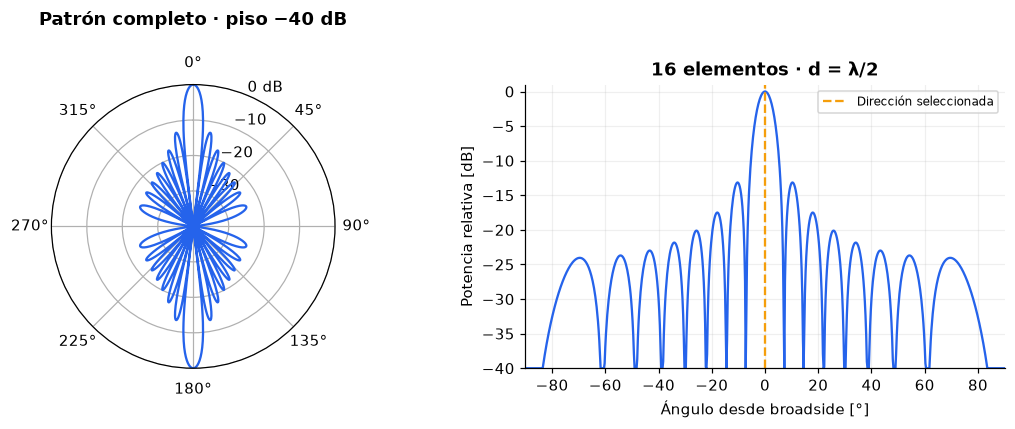

In [10]:
def patron_ula(theta_rad, elementos=16, direccion_deg=0):
    fase = np.pi * (np.sin(theta_rad) - np.sin(np.deg2rad(direccion_deg)))
    campo = np.mean(np.exp(1j*np.arange(elementos)[:, None]*fase[None, :]), axis=0)
    return np.abs(campo)**2

def dibujar_antena(elementos=16, direccion_deg=0):
    theta = np.linspace(-np.pi, np.pi, 1441)
    potencia = patron_ula(theta, elementos, direccion_deg)
    relativo_db = 10*np.log10(np.maximum(potencia, 1e-4))
    fig = plt.figure(figsize=(10, 4))
    polar = fig.add_subplot(121, projection="polar")
    polar.plot(theta, relativo_db+40, color="#2563EB")
    polar.set_theta_zero_location("N"); polar.set_theta_direction(-1)
    polar.set_ylim(0, 40); polar.set_yticks([10,20,30,40])
    polar.set_yticklabels(["−30", "−20", "−10", "0 dB"])
    polar.set_title("Patrón completo · piso −40 dB", pad=20)
    ax = fig.add_subplot(122)
    frontal = np.abs(theta) <= np.pi/2
    ax.plot(np.rad2deg(theta[frontal]), relativo_db[frontal], color="#2563EB")
    ax.axvline(direccion_deg, color="#F59E0B", linestyle="--", label="Dirección seleccionada")
    ax.set(xlabel="Ángulo desde broadside [°]", ylabel="Potencia relativa [dB]",
           ylim=(-40, 1), xlim=(-90,90), title=f"{elementos} elementos · d = λ/2")
    ax.grid(alpha=0.2); ax.legend(fontsize=8)
    fig.tight_layout(); plt.show()

dibujar_antena()

**Interpreta el gráfico.** A la izquierda, el patrón completo en coordenadas polares; a la derecha, el corte frontal en dB. El lóbulo principal apunta a 0°; a ambos lados hay nulos y lóbulos laterales unos 13 dB por debajo del máximo, propios de un arreglo de amplitudes iguales. El haz posterior aparece porque los elementos isotrópicos radian igual hacia atrás; una antena real usa un reflector o elementos directivos.

**Predice antes de mover:** ¿qué pasa con el ancho al pasar de 8 a 32 elementos?
¿Cambiar dirección crea potencia o redistribuye la respuesta?
Ejecuta la siguiente celda para activar controles. Si no aparecen, cambia los argumentos de `dibujar_antena(8, 20)`.
La función ya está escrita: tu tarea es explorar y explicar.

> **Python nuevo · `try` / `except`.** La celda siguiente intenta crear los controles. Si la librería `ipywidgets` no está disponible, `except ImportError:` ejecuta el bloque alternativo en lugar de detener el notebook con un error.

In [11]:
try:
    import ipywidgets as widgets
    control_antena = widgets.interactive(
        dibujar_antena,
        elementos=widgets.IntSlider(value=16, min=8, max=32, step=4, description="Elementos", continuous_update=False),
        direccion_deg=widgets.IntSlider(value=0, min=-30, max=30, step=5, description="Dirección °", continuous_update=False))
    display(control_antena)
except ImportError:
    print("Sin widgets: ejecuta dibujar_antena(8, 20).")

**De la antena al receptor: ganancia, polarización y cable.**

La ganancia lineal cumple $G=\eta D$, con η la eficiencia y D la directividad; en dBi, $10\log_{10}G$.
dBi = dBd + 2.15. El área efectiva es $A_e=G\lambda^2/(4\pi)$.
Para una parábola ideal aproximada de diámetro $d_{ap}$: $G\approx\eta(\pi d_{ap}/\lambda)^2$.
Una apertura mayor estrecha el haz; no fabrica energía.

En polarización lineal ideal, el factor recibido es $\cos^2\alpha$, con α el ángulo entre las polarizaciones.
A 45° hay 3.01 dB de pérdida; a 90° el modelo da recepción nula.

Un feeder atenúa y puede reflejar. Para cargas resistivas:
$$\Gamma=\frac{Z_L-Z_0}{Z_L+Z_0},\quad VSWR=\frac{1+|\Gamma|}{1-|\Gamma|},\quad
RL=-20\log_{10}|\Gamma|.$$
Potencia reflejada: $|\Gamma|^2$; pérdida por desadaptación: $-10\log_{10}(1-|\Gamma|^2)$.
$Z_0$ es impedancia característica, no la resistencia DC de un cable; $Z_L$ es la impedancia de la carga.

In [12]:
gamma = (75-50)/(75+50)
print(f"Γ: {gamma:.2f}; VSWR: {(1+abs(gamma))/(1-abs(gamma)):.2f}")
print(f"Reflejada: {100*abs(gamma)**2:.1f}%; retorno: {-20*np.log10(abs(gamma)):.3f} dB")
print(f"Mismatch: {-10*np.log10(1-abs(gamma)**2):.3f} dB")

Γ: 0.20; VSWR: 1.50
Reflejada: 4.0%; retorno: 13.979 dB
Mismatch: 0.177 dB


**Interpreta.** Una línea de 50 Ω conectada a una carga de 75 Ω refleja el 4% de la potencia (Γ = 0.2, VSWR = 1.5). La pérdida por desadaptación es solo 0.18 dB; aun así, la onda reflejada vuelve hacia el transmisor y forma ondas estacionarias en la línea.

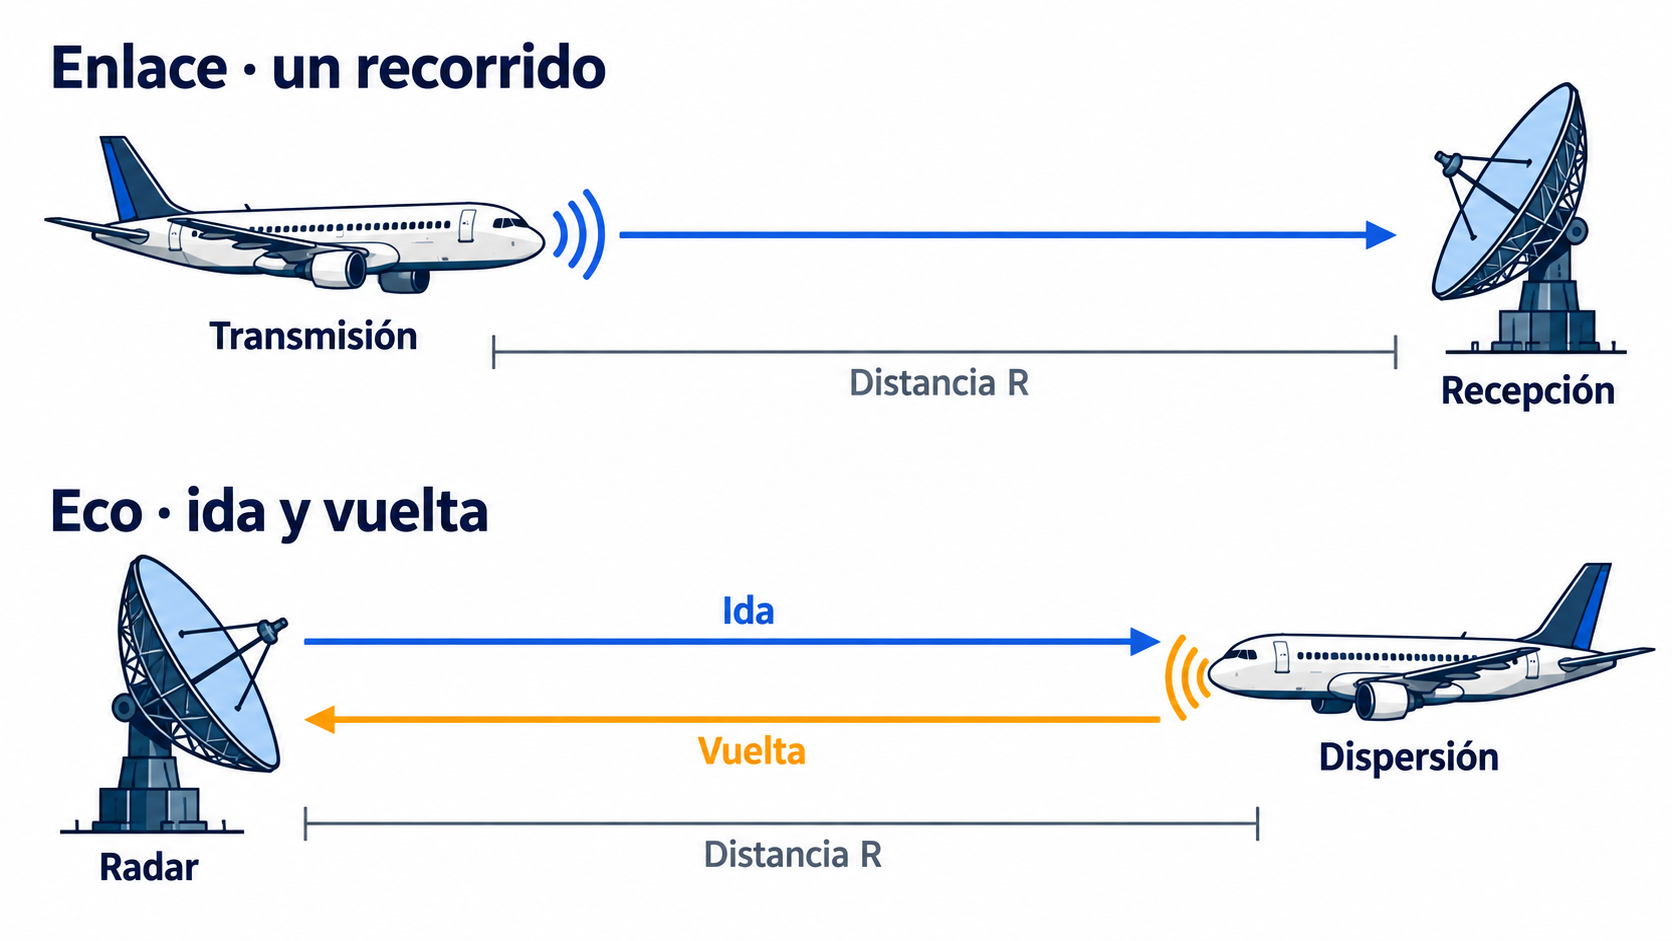

## 6 · La ecuación radar: el viaje de ida y vuelta

**El problema.** Un radar primario (PSR) no necesita que el avión coopere: emite un pulso, una pequeña parte de la energía rebota en el avión y regresa. ¿Cuánta potencia vuelve?

**Intuición.** La energía hace **dos** viajes. A la ida se dispersa como en un enlace (∝ 1/R²); el avión reirradia una fracción, que vuelve a dispersarse en el regreso (otro 1/R²). Resultado: 1/R⁴.

**Modelo (radar monostático idealizado: transmite y recibe con la misma antena):**
$$P_r=\frac{P_tG^2\lambda^2\sigma}{(4\pi)^3R^4L}.$$

| Símbolo | Significado | Valor en el ejemplo |
|---|---|---|
| $P_t$ | Potencia de pico transmitida | 50 kW |
| $G$ | Ganancia de la antena, factor lineal; aparece al cuadrado porque la antena transmite y recibe | 30 dBi = 1000 |
| $\lambda$ | Longitud de onda | c / 2.7 GHz ≈ 0.111 m |
| $\sigma$ | Sección radar (RCS): área equivalente que «ve» el radar, no el área física del avión | 10 m² |
| $R$ | Distancia radar–blanco | m |
| $L$ | Pérdidas del sistema, factor lineal | 3 dB ≈ 2 |

El exponente 4 combina propagación de ida y de retorno.
Duplicar distancia divide la potencia por 16: **−12.04 dB**.

El umbral ilustrativo es −110 dBm.
El cruce de la curva con el umbral es un límite de este modelo, no alcance operacional:
no modelamos probabilidad de detección, clutter, fluctuación de σ ni procesamiento.

> **Python nuevo ·** `np.asarray(r_m)` acepta un número o un array: la misma función calcula un valor o una curva completa. En `dibujar_radar`, el alcance límite despeja R de la ecuación: como $P_r\propto R^{-4}$, $R_{lim}=1\,\text{km}\cdot\left(P_r(1\,\text{km})/P_{umbral}\right)^{1/4}$; `**0.25` es la raíz cuarta. `ax.axhline` y `ax.axvline` trazan una línea horizontal y una vertical: aquí, el umbral y el alcance límite.

Eco a 60 km: -99.197 dBm
Al duplicar R: -12.041 dB


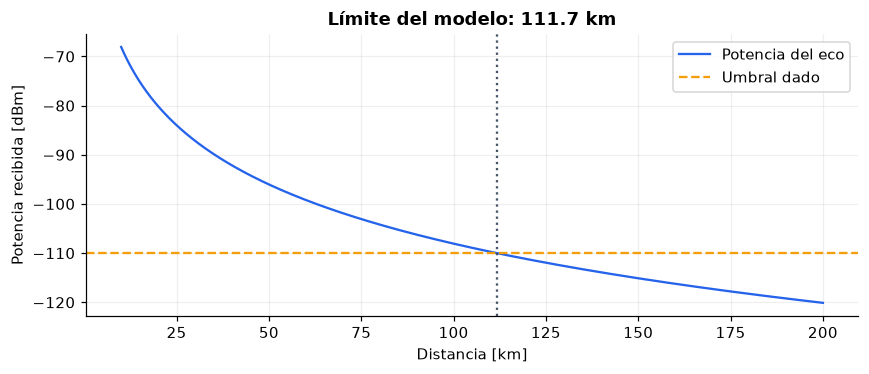

In [13]:
def radar_w(r_m, pico_kw=50, ganancia_dbi=30, sigma_m2=10):
    g = db_a_factor(ganancia_dbi)
    return pico_kw*1000 * g**2 * (C/2.7e9)**2 * sigma_m2 / ((4*np.pi)**3 * np.asarray(r_m)**4 * db_a_factor(3))

def dibujar_radar(pico_kw=50, ganancia_dbi=30, sigma_m2=10):
    dist_km = np.linspace(10, 200, 500)
    pr = w_a_dbm(radar_w(dist_km*1000, pico_kw, ganancia_dbi, sigma_m2))
    referencia_w = 1e-3 * db_a_factor(-110)
    limite_km = (radar_w(1000, pico_kw, ganancia_dbi, sigma_m2)/referencia_w)**0.25
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(dist_km, pr, color="#2563EB", label="Potencia del eco")
    ax.axhline(-110, color="#F59E0B", linestyle="--", label="Umbral dado")
    ax.axvline(limite_km, color="#475569", linestyle=":")
    ax.set(xlabel="Distancia [km]", ylabel="Potencia recibida [dBm]", title=f"Límite del modelo: {limite_km:.1f} km")
    ax.grid(alpha=0.2); ax.legend(); fig.tight_layout(); plt.show()

print(f"Eco a 60 km: {w_a_dbm(radar_w(60e3)):.3f} dBm")
print(f"Al duplicar R: {10*np.log10(radar_w(120e3)/radar_w(60e3)):.3f} dB")
dibujar_radar()

**Interpreta.** A 60 km el eco vale unos −99 dBm: de 50 kW transmitidos vuelven ~10⁻¹³ W. La curva cae 12 dB cada vez que la distancia se duplica. El cruce con el umbral (línea discontinua) da el alcance **de este modelo**.

### Enlace frente a eco: R⁻² frente a R⁻⁴

El gráfico siguiente compara ambas leyes, normalizadas a 0 dB en 10 km. Con el eje de distancia en **escala logarítmica**, cada ley de potencia se convierte en una recta cuya pendiente indica cuántos dB se pierden cada vez que la distancia se multiplica por 10.

> **Python nuevo ·** `ax.semilogx` dibuja con el eje x logarítmico: 10, 20, 50 y 100 km quedan separados según sus cocientes, no según sus diferencias.

**Predice:** entre 10 y 100 km, ¿cuántos dB perderá cada curva?

De 10 a 100 km → enlace: -20.0 dB; eco: -40.0 dB


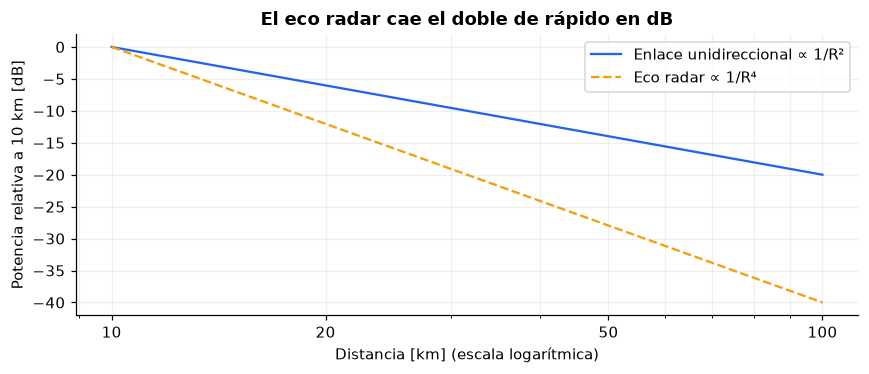

In [14]:
distancias_km = np.linspace(10, 100, 400)
enlace_db = 10*np.log10((10/distancias_km)**2)   # enlace: un recorrido
eco_db = 10*np.log10((10/distancias_km)**4)      # radar: ida y vuelta
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.semilogx(distancias_km, enlace_db, color="#2563EB", label="Enlace unidireccional ∝ 1/R²")
ax.semilogx(distancias_km, eco_db, color="#F59E0B", linestyle="--", label="Eco radar ∝ 1/R⁴")
ax.set(xlabel="Distancia [km] (escala logarítmica)", ylabel="Potencia relativa a 10 km [dB]",
       title="El eco radar cae el doble de rápido en dB")
ax.set_xticks([10, 20, 50, 100], ["10", "20", "50", "100"])
ax.grid(alpha=0.2, which="both"); ax.legend(); fig.tight_layout(); plt.show()
print(f"De 10 a 100 km → enlace: {enlace_db[-1]:.1f} dB; eco: {eco_db[-1]:.1f} dB")

**Interpreta.** Cuando la distancia se multiplica por 10, el enlace pierde 20 dB y el eco 40 dB. Por eso un radar primario necesita pulsos de decenas de kW, mientras que en el enlace cooperativo de §4 bastaban 100 W: allí la señal sale del propio avión y recorre el camino una sola vez.

**Explora:** duplica potencia de transmisión. El límite crece solo $2^{1/4}\approx1.189$ veces.
Subir 3 dB la ganancia aumenta casi 6 dB el eco porque la antena interviene dos veces.
Mantén fijos los demás parámetros al comparar.

In [15]:
try:
    control_radar = widgets.interactive(
        dibujar_radar,
        pico_kw=widgets.IntSlider(value=50, min=10, max=100, step=10, description="Pico kW", continuous_update=False),
        ganancia_dbi=widgets.IntSlider(value=30, min=20, max=40, description="G dBi", continuous_update=False),
        sigma_m2=widgets.FloatSlider(value=10, min=1, max=20, step=1, description="σ m²", continuous_update=False))
    display(control_radar)
except (ImportError, NameError):
    print("Sin widgets: ejecuta dibujar_radar(100, 30, 10).")

## 7 · Del tiempo a la observación

**El problema.** Un sistema de vigilancia necesita saber **dónde** está cada avión. Las tecnologías difieren en qué miden y en cuánto dependen del avión:

- **PSR (radar primario):** no cooperativo. Mide el eco; detecta incluso un avión sin transpondedor. La distancia sale del tiempo de ida y vuelta, $R=c\Delta t/2$: el 2 aparece porque el pulso recorre la distancia dos veces.
- **SSR (radar secundario, modos A/C y S):** cooperativo. El radar **interroga** y el transpondedor del avión **responde** tras un retardo $t_d$, que se resta antes de dividir por 2.
- **ADS-B:** cooperativo y dependiente. El avión **difunde**, sin ser interrogado, la posición que calcula su propio sistema de navegación, normalmente GNSS. El receptor no mide la distancia: decodifica un mensaje.
- **MLAT:** varios receptores miden diferencias de tiempo de llegada (TDoA) de las mismas transmisiones del avión.

| Tecnología | Qué observa o recibe | Qué debes cuidar |
|---|---|---|
| PSR | Eco; $R=c\Delta t/2$ | RCS, clutter, umbral y asociación |
| SSR A/C o Mode S | Respuesta; $R=c(\Delta t-t_d)/2$ | Retardo y referencia temporal; A: código, C: altitud, S: direccionamiento/datos |
| ADS-B | Posición reportada en difusión | Fuente de a bordo, tiempo y calidad |
| MLAT | Diferencias de llegada; $\Delta d=c\Delta t$ | Sincronización, geometría y receptores válidos |

SSR interroga en 1030 MHz y recibe en 1090 MHz. ADS-B no es una medida de distancia por eco.
GNSS es una familia de sistemas; GPS es uno. ADS-C reporta por contrato, no por broadcast.
Una sola pareja TDoA define una curva, no una posición única.

Un **plot** es una detección; un **track** asocia observaciones a través del tiempo.
Fusionar exige procedencia, tiempo y calidad: no basta con promediar posiciones.

In [16]:
eco_s = 400e-6
print(f"PSR: {C*eco_s/2/1000:.1f} km")
print(f"TDoA de 100 ns: {C*100e-9:.1f} m de diferencia de camino")
print(f"Resolución sin compresión, τ=1 µs: {C*1e-6/2:.0f} m")
print(f"Alcance no ambiguo, PRF=2000 Hz: {C/(2*2000)/1000:.0f} km")
print(f"Actualización a 6 rpm: {60/6:.0f} s por giro")

PSR: 60.0 km
TDoA de 100 ns: 30.0 m de diferencia de camino
Resolución sin compresión, τ=1 µs: 150 m
Alcance no ambiguo, PRF=2000 Hz: 75 km
Actualización a 6 rpm: 10 s por giro


**Interpreta.** 400 µs de ida y vuelta corresponden a 60 km. Si los pulsos se repiten cada 500 µs (PRF = 2000 Hz), un eco que tarde más llega después del pulso siguiente y se confunde con un blanco cercano: por eso el alcance no ambiguo es 75 km. Una diferencia de llegada de 100 ns equivale a 30 m de diferencia de camino: MLAT exige relojes muy bien sincronizados.

Resolución separa blancos; precisión describe error de medida; alcance no ambiguo evita confundir pulsos.
Son propiedades distintas. Con ancho de banda efectivo B, una aproximación de resolución es $c/(2B)$.
Una antena de 1° a 6 rpm ilumina una dirección durante $1/(6\cdot6)$ s;
a 2000 Hz caben unos 56 pulsos, distintos de los 10 s entre giros.

## 8 · Convertir y transportar información

**El problema.** Entre la antena y la pantalla del controlador, la señal se convierte en bits y los bits en mensajes. Cada etapa puede fallar de forma distinta.

La cadena distingue fuente → codificación → modulación → canal → demodulación → decodificación → destino.
AM cambia amplitud; FM, frecuencia; PM, fase. Sus familias digitales incluyen ASK/OOK, FSK y PSK.
**PPM cambia la posición del pulso**, no su presencia. En Mode S y ADS-B, cada bit dura 1 µs: un **1** lleva el pulso en la primera mitad del intervalo y un **0**, en la segunda. La figura usa esa convención.

> **Python nuevo ·** `np.where(condición, a, b)` elige elemento a elemento: `a` donde la condición es `True` y `b` donde es `False`. `np.linspace(0, 4, 1600, endpoint=False)` excluye el extremo final. `bits[indice]` usa un array de posiciones para tomar, en cada instante, el bit que le corresponde. `.astype(int)` y `.astype(float)` convierten el tipo de los elementos (por ejemplo, `True` → 1.0). `ax.step` dibuja escalones, adecuados para señales digitales; `sharex=True` hace que los tres gráficos compartan el eje de tiempo.

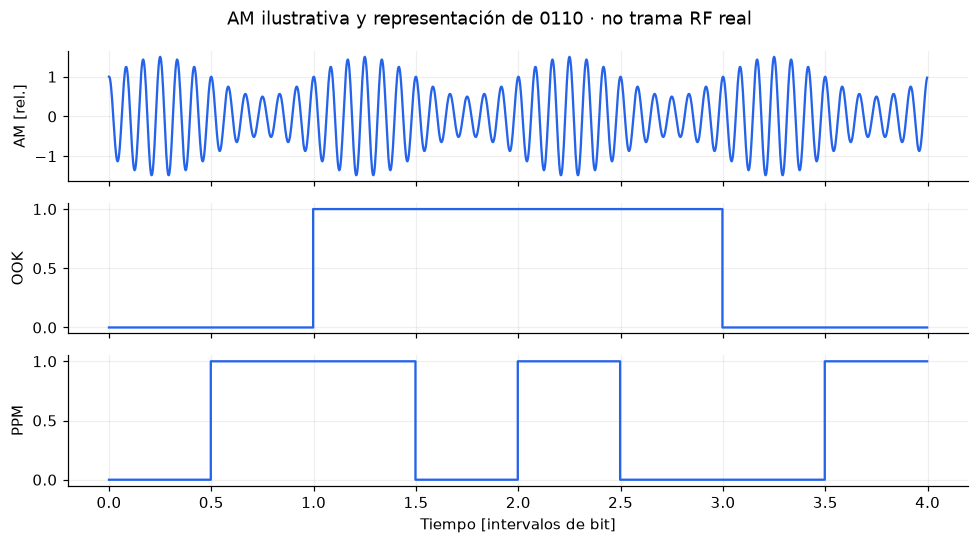

In [17]:
bits = np.array([0, 1, 1, 0])
t_bit = np.linspace(0, 4, 1600, endpoint=False)
indice = t_bit.astype(int)
fraccion = t_bit - indice
ook = bits[indice]
ppm = np.where(bits[indice] == 1, fraccion < 0.5, fraccion >= 0.5).astype(float)
portadora = np.cos(2*np.pi*12*t_bit)
am = (1+0.5*np.sin(2*np.pi*t_bit))*portadora
fig, ax = plt.subplots(3, 1, figsize=(9, 5), sharex=True)
ax[0].plot(t_bit, am, color="#2563EB"); ax[0].set_ylabel("AM [rel.]")
ax[1].step(t_bit, ook, color="#2563EB"); ax[1].set_ylabel("OOK")
ax[2].step(t_bit, ppm, color="#2563EB"); ax[2].set_ylabel("PPM")
ax[2].set_xlabel("Tiempo [intervalos de bit]")
for a in ax: a.grid(alpha=0.2)
fig.suptitle("AM ilustrativa y representación de 0110 · no trama RF real")
fig.tight_layout(); plt.show()

**Interpreta.** OOK enciende o apaga el nivel según el bit: un 0 es silencio. PPM emite siempre un pulso por bit y codifica el valor en su posición, así que el receptor ve energía en todos los intervalos. Cuando un 0 va seguido de un 1, ambos pulsos quedan contiguos y se ven como uno solo, más largo: el receptor decide cada bit comparando las dos mitades de su intervalo. **Experimenta:** cambia `bits` a `np.array([1, 0, 1, 0])` y comprueba la posición de cada pulso.

**Muestreo y cuantización.** En banda base limitada, el modelo ideal pide $f_s>2f_{max}$ (frecuencia de muestreo mayor que el doble de la máxima frecuencia de la señal) y un filtro antialias previo.
Muestrear a 5 MHz una señal baseband de 1 MHz no equivale a muestrear RF de 1090 MHz.
Un ADC de N bits tiene $2^N$ niveles y paso $\Delta=FSR/2^N$, con FSR el rango total de entrada en V.
Para un seno ideal a escala completa, $SQNR\approx6.02N+1.76$ dB. Resolución no es precisión.

Un bit admite 2 estados; un nibble, 4 bits; un byte, 8. Un símbolo puede representar varios bits:
$R_b=R_s\log_2M$, con $R_s$ símbolos por segundo y M estados por símbolo. Un campo adquiere significado mediante un protocolo.

> **Python nuevo ·** `int("1010", 2)` interpreta el texto como un número en base 2; `int("A", 16)`, en base 16 (hexadecimal).

In [18]:
print("1010 binario:", int("1010", 2), "· A hexadecimal:", int("A", 16))
print(f"ADC de 10 bits y 2 V: {2/2**10*1000:.6f} mV por nivel")
print(f"112 bits a 1 Mbit/s + preámbulo dado de 8 µs: {(112/1e6+8e-6)*1e6:.0f} µs")

1010 binario: 10 · A hexadecimal: 10
ADC de 10 bits y 2 V: 1.953125 mV por nivel
112 bits a 1 Mbit/s + preámbulo dado de 8 µs: 120 µs


**Interpreta.** Un ADC de 10 bits divide 2 V en 1024 escalones de ~1.95 mV: variaciones menores no se distinguen. Un mensaje de 112 bits a 1 Mbit/s, más su preámbulo, ocupa 120 µs en el aire.

Los 112 bits del ejemplo **ya incluyen** 24 de paridad; no los sumes otra vez.
Un umbral produce una detección, que puede ser falsa positiva o falsa negativa.
Detectar una señal no equivale a decodificar un mensaje. Paridad/CRC comprueba integridad bajo un modelo,
no veracidad de posición ni creación de un track.

## 9 · La red también participa

$t_{serie}=L_{bits}/R_{bit/s}$; $t_{prop}=d/v$.
La latencia total suma serialización, propagación, procesamiento y cola en el recorrido definido.
Jitter es variación de retardo; aquí usaremos máximo menos mínimo.
PLR = paquetes perdidos/enviados.

La disponibilidad modelada es $A=MTBF/(MTBF+MTTR)$.
Para dos rutas independientes, cualquiera suficiente: $A_{2}=1-(1-A)^2$.
Una causa común rompe la hipótesis de independencia.

In [19]:
serie_s = 200*8/1e6
prop_s = 20e3/2e8
print(f"Latencia sin overhead: {(serie_s+prop_s+2e-3+5e-3)*1e3:.1f} ms")
retardos_ms = np.array([8, 9, 12, 8])
print(f"Jitter definido como rango: {np.ptp(retardos_ms):.0f} ms")
a = 1000/(1000+2)
print(f"Una ruta: {100*a:.6f}%; dos independientes: {100*(1-(1-a)**2):.9f}%")

Latencia sin overhead: 8.7 ms
Jitter definido como rango: 4 ms
Una ruta: 99.800399%; dos independientes: 99.999601595%


**Interpreta.** La latencia de este ejemplo la dominan cola y procesamiento (7 ms), no la propagación por 20 km de fibra (0.1 ms). `np.ptp` («peak to peak») calcula máximo menos mínimo. Dos rutas independientes llevan la disponibilidad de 99.8% a 99.9996%, siempre que no compartan una causa común de falla.

| Capa | Evidencia útil |
|---|---|
| Física | Alimentación, medio, nivel RF, conectividad |
| Enlace | Tramas y errores; MAC identifica interfaces |
| Red | Direccionamiento IP, ruta, LAN/WAN |
| Transporte | UDP: datagramas; TCP: flujo fiable ordenado, con costos de recuperación |
| Aplicación | Formato del mensaje, timestamp, origen y calidad |

El tiempo de llegada no siempre es el de observación. Un dato observado a 12:00:00 y recibido a 12:00:02
ya tiene 2 s de edad. El enlace activo no prueba que el centro reciba información vigente.

Un nodo procesa o conecta; un enlace transporta entre nodos. LAN conecta un ámbito local y WAN une ámbitos separados. Cobre, fibra y radio difieren en velocidad de propagación, pérdidas y susceptibilidad. Capacidad en bit/s no es ancho de banda físico en Hz.

## Explora más · Modelos que completan la cadena

Estas cápsulas amplían los cálculos anteriores. En cada una, identifica qué supuesto hace válida la fórmula.

### A · Circuitos y energía

Kirchhoff: la suma de corrientes en un nodo y de voltajes orientados en un lazo se conserva.
En serie se suman resistencias; en paralelo se suman conductancias. El divisor siguiente supone salida sin carga.
En RLC serie, $Z=R+j(2\pi fL-1/(2\pi fC))$.
$S=V_{rms}I_{rms}$ en VA; $P=S\,FP$ en W. Para senos ideales, $FP=\cos\phi$.

In [20]:
r1, r2 = 100, 200
print(f"Serie: {r1+r2} Ω; paralelo: {1/(1/r1+1/r2):.3f} Ω")
print(f"Divisor sin carga, 12 V: {12*r2/(r1+r2):.1f} V")
print(f"Nodo: entran 5 A, salen 2 A y {5-2} A")
print(f"Lazo orientado: 12 - 4 - 8 = {12-4-8} V")
z = 10 + 1j*(2*np.pi*1000*10e-3 - 1/(2*np.pi*1000*1e-6))
print(f"|Z| RLC: {abs(z):.3f} Ω; fase: {np.angle(z, deg=True):.2f}°")
print(f"230 V, 2 A, FP=0.8: S={230*2} VA; P={230*2*0.8} W")
print(f"1 Wh = {3600} J; voltaje 12 V = 24 J / 2 C")
paralelo_cargado = 1/(1/r2 + 1/200)
print(f"Divisor cargado con 200 Ω: {12*paralelo_cargado/(r1+paralelo_cargado):.1f} V")

Serie: 300 Ω; paralelo: 66.667 Ω
Divisor sin carga, 12 V: 8.0 V
Nodo: entran 5 A, salen 2 A y 3 A
Lazo orientado: 12 - 4 - 8 = 0 V
|Z| RLC: 96.841 Ω; fase: -84.07°
230 V, 2 A, FP=0.8: S=460 VA; P=368.0 W
1 Wh = 3600 J; voltaje 12 V = 24 J / 2 C
Divisor cargado con 200 Ω: 6.0 V


Masa es una referencia de circuito; tierra de protección cumple otra función. Un bucle de referencias puede
introducir perturbación. Un circuito abierto interrumpe el camino; un corto crea un camino de baja impedancia.
Huecos, sobretensiones, transitorios, interrupciones y ruido conducido afectan de formas distintas.
**Piensa:** ¿un fusible intacto prueba que la carga recibe tensión adecuada?

En serie circula la misma corriente; en paralelo las ramas comparten tensión. Una protección limita consecuencias, no certifica funcionamiento. Una carga conectada al divisor modifica su resistencia equivalente y su salida.

### B · Ruido, ancho de banda y decisiones

Un seno periódico, un pulso transitorio y ruido aleatorio son señales diferentes.
El siguiente ruido tiene semilla fija: la repetición permite comparar SNR.
En cascada: $F_{total}=F_1+(F_2-1)/G_1$ con factores **lineales**.
Una pérdida anterior al LNA degrada la cadena; su ubicación importa.
Shannon: $C=B\log_2(1+SNR)$, un límite de canal ideal, no capacidad de servicio garantizada.

Clasifica por ejes distintos: continuo/discreto en tiempo, analógico/digital en representación, periódico/no periódico y determinista/aleatorio. El osciloscopio muestra variación temporal; el analizador de espectro muestra componentes de frecuencia. La ganancia automática (AGC) regula nivel interno; no mejora por sí sola SNR de entrada.

> **Python nuevo ·** `rng = np.random.default_rng(42)` crea un generador de números aleatorios con **semilla** fija: produce siempre el mismo ruido, así todos obtienen el mismo resultado. Con arrays de `bool`, `a & b` es «y» elemento a elemento y `~a` invierte cada valor.

In [21]:
rng = np.random.default_rng(42)
senal = np.sin(2*np.pi*50*np.arange(2000)/2000)
ruido = rng.normal(0, 0.2, len(senal))
print(f"SNR medido: {10*np.log10(np.mean(senal**2)/np.mean(ruido**2)):.2f} dB")
f_total = db_a_factor(2) + (db_a_factor(8)-1)/db_a_factor(20)
print(f"NF cascada (2 dB / 20 dB de G; luego 8 dB NF): {10*np.log10(f_total):.3f} dB")
print(f"Shannon, B=1 MHz, SNR=10 dB: {1e6*np.log2(1+db_a_factor(10))/1e6:.3f} Mbit/s")
verdad = np.array([True, False, True, False])
amplitudes = np.array([0.8, 0.7, 0.3, 0.2])
detectado = amplitudes > 0.5
print("Falsos positivos:", np.count_nonzero(detectado & ~verdad))
print("Falsos negativos:", np.count_nonzero(~detectado & verdad))

SNR medido: 10.94 dB
NF cascada (2 dB / 20 dB de G; luego 8 dB NF): 2.143 dB
Shannon, B=1 MHz, SNR=10 dB: 3.459 Mbit/s
Falsos positivos: 1
Falsos negativos: 1


### C · Medio, caminos y perturbaciones

En un medio ideal no magnético, $v\approx c/\sqrt{\epsilon_r}$.
Una línea ideal tiene $Z_0\approx\sqrt{L'/C'}$; sus parámetros son por unidad de longitud.
Un feeder con atenuación α dB/m y longitud ℓ pierde αℓ dB.

| Fenómeno | Qué cambia |
|---|---|
| Reflexión | Aparece un camino adicional |
| Absorción | Parte de la energía se disipa en el medio |
| Difracción | El campo rodea un obstáculo con pérdidas |
| Refracción | Cambia la dirección por el medio |
| Multitrayecto | Se suman copias con distintos retardos y fases |

No todos los materiales o frecuencias se comportan igual. Una copia puede reforzar o cancelar otra.
En espacio libre, duplicar distancia resta 6.02 dB en un enlace; en eco radar resta 12.04 dB.
Duplicar frecuencia suma 6.02 dB de FSPL **con ganancias fijas**.

εr=4: velocidad 1.5e+08 m/s
L'=250 nH/m, C'=100 pF/m: Z0=50.0 Ω
Feeder 20 m a 0.05 dB/m: 1.0 dB
Camino extra de 30 m: 100 ns
 118 MHz → λ=2.5424 m
1030 MHz → λ=0.2913 m
1090 MHz → λ=0.2752 m
2700 MHz → λ=0.1111 m
9000 MHz → λ=0.0333 m


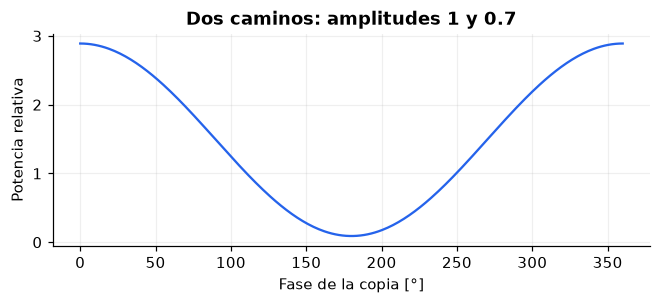

In [22]:
print(f"εr=4: velocidad {C/np.sqrt(4):.3g} m/s")
print(f"L'=250 nH/m, C'=100 pF/m: Z0={np.sqrt(250e-9/100e-12):.1f} Ω")
print(f"Feeder 20 m a 0.05 dB/m: {20*0.05:.1f} dB")
print(f"Camino extra de 30 m: {30/C*1e9:.0f} ns")
fase = np.linspace(0, 2*np.pi, 301)
potencia_rel = np.abs(1 + 0.7*np.exp(1j*fase))**2
fig, ax = plt.subplots(figsize=(7, 2.5))
ax.plot(np.rad2deg(fase), potencia_rel, color="#2563EB")
ax.set(xlabel="Fase de la copia [°]", ylabel="Potencia relativa", title="Dos caminos: amplitudes 1 y 0.7")
ax.grid(alpha=0.2); plt.show()
for mhz in [118, 1030, 1090, 2700, 9000]:
    print(f"{mhz:4d} MHz → λ={C/(mhz*1e6):.4f} m")

118 MHz se ubica en VHF; 1030/1090 MHz, en UHF según la clasificación por décadas.
2.7 GHz corresponde a S y 9 GHz a X en bandas radar usuales. Los nombres de distintas clasificaciones pueden solaparse.

Cocanal comparte canal; adyacente proviene de un canal vecino; intermodulación crea productos en una no linealidad;
autointerferencia procede del propio sistema; ruido industrial puede acoplarse al receptor.
Para SINR suma ruido e interferencia en potencia lineal, no en dBm.

> **Python nuevo ·** La primera línea de la celda siguiente es una comprensión de lista (Laboratorio 01, sección 6) que convierte tres niveles en dBm a W; después reparte los tres resultados en tres variables.

In [23]:
s_w, n_w, i_w = [1e-3*db_a_factor(v) for v in [-80, -100, -90]]
print(f"SINR: {10*np.log10(s_w/(n_w+i_w)):.3f} dB")
g_lineal = 0.6 * 100
print(f"Directividad D=100 y eficiencia 60%: G={g_lineal:.0f}, {10*np.log10(g_lineal):.3f} dBi")
lam = C/2.7e9
g_parabola = 0.6*(np.pi*2/lam)**2
print(f"Parábola de 2 m de diámetro, η=0.6: {10*np.log10(g_parabola):.3f} dBi")
print(f"Área efectiva: {g_parabola*lam**2/(4*np.pi):.3f} m²")
print(f"Haz aproximado 70λ/diámetro: {70*lam/2:.3f}° (modelo de apertura dado)")
print(f"Densidad a 1 km, Pt=1 W, G=10: {1*10/(4*np.pi*1000**2):.3g} W/m²")
print(f"90° de desalineación ideal: potencia recibida cero; pérdida en dB no finita")

SINR: 9.586 dB
Directividad D=100 y eficiencia 60%: G=60, 17.782 dBi
Parábola de 2 m de diámetro, η=0.6: 32.830 dBi
Área efectiva: 1.885 m²
Haz aproximado 70λ/diámetro: 3.889° (modelo de apertura dado)
Densidad a 1 km, Pt=1 W, G=10: 7.96e-07 W/m²
90° de desalineación ideal: potencia recibida cero; pérdida en dB no finita


### D · Aliasing y geometría de localización

Un seno de 7 Hz muestreado a 10 Hz comparte muestras con un seno de −3 Hz: la información original se pierde.
El filtro previo evita que componentes fuera de banda entren al muestreo.
Con M=4 símbolos y 1000 símbolos/s, caben 2000 bits/s en el modelo sin overhead.

M=4 y Rs=1000: 2000 bit/s


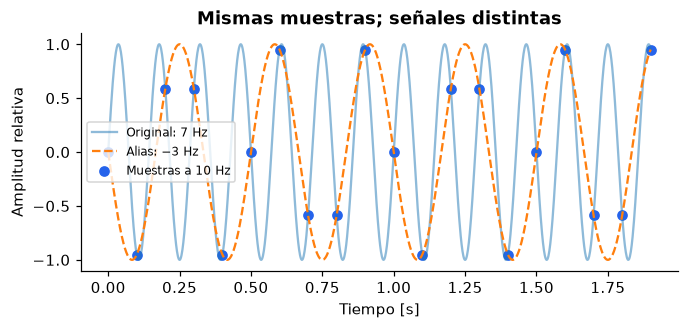

In [24]:
tiempos = np.arange(20)/10
fig, ax = plt.subplots(figsize=(7, 2.8))
continuo = np.linspace(0, 1.9, 1200)
ax.plot(continuo, np.sin(2*np.pi*7*continuo), alpha=0.5, label="Original: 7 Hz")
ax.plot(continuo, np.sin(-2*np.pi*3*continuo), linestyle="--", label="Alias: −3 Hz")
ax.scatter(tiempos, np.sin(2*np.pi*7*tiempos), color="#2563EB", label="Muestras a 10 Hz")
ax.set(xlabel="Tiempo [s]", ylabel="Amplitud relativa", title="Mismas muestras; señales distintas")
ax.legend(fontsize=8); plt.show()
print(f"M=4 y Rs=1000: {1000*np.log2(4):.0f} bit/s")

La geometría TDoA se dibuja con receptores A=(−10,0) km y B=(10,0) km.
La diferencia dA−dB=3 km corresponde a 10 µs. Todos los puntos de la curva satisfacen esa misma medición:
necesitamos más observaciones independientes y buena geometría para localizar.

> **Python nuevo ·** `np.meshgrid` crea una rejilla de puntos (x, y); `np.hypot(dx, dy)` calcula la distancia $\sqrt{dx^2+dy^2}$ en cada punto; `ax.contour(..., levels=[3])` dibuja la curva donde la diferencia vale exactamente 3 km.

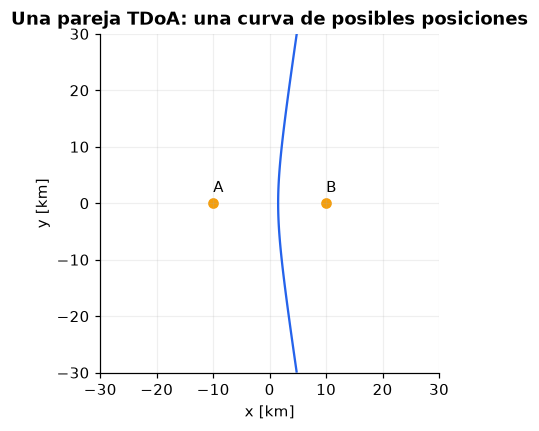

In [25]:
xx, yy = np.meshgrid(np.linspace(-30,30,401), np.linspace(-30,30,401))
diferencia_km = np.hypot(xx+10, yy) - np.hypot(xx-10, yy)
fig, ax = plt.subplots(figsize=(6, 4))
ax.contour(xx, yy, diferencia_km, levels=[3], colors=["#2563EB"])
ax.scatter([-10,10], [0,0], color="#F59E0B")
ax.annotate("A",(-10,0),xytext=(-10,2)); ax.annotate("B",(10,0),xytext=(10,2))
ax.set(xlabel="x [km]", ylabel="y [km]", title="Una pareja TDoA: una curva de posibles posiciones")
ax.set_aspect("equal"); ax.grid(alpha=0.2); plt.show()

## Misión final · Un puesto de vigilancia bajo revisión

Completa las doce hojas de cálculo de un mismo diagnóstico. Los datos pertenecen a modelos sintéticos;
las condiciones de cada hoja se declaran por separado. Usa las fórmulas anteriores y conserva SI internamente.
`mostrar()` compara números con tolerancia y deja pendientes los `None`.
Las referencias están redondeadas para lectura; calcula con toda la precisión disponible.

**Regla de cierre:** un margen favorable en RF no demuestra integridad del mensaje, sincronización o continuidad de servicio.

**Cómo trabajar cada hoja:**

1. Lee los datos y conviértelos a SI (µs → `1e-6` s, MHz → `1e6` Hz, mm² → `1e-6` m²).
2. Identifica la fórmula en la sección indicada.
3. Escribe una línea por variable, en el orden de la lista.
4. Ejecuta y compara con la salida esperada.
5. Si aparece «revisa», comprueba unidades y prefijos antes de cambiar la fórmula.

### Q01 · El camino eléctrico

Fuente 48 V, corriente constante 3 A, cobre con ρ=1.68e−8 Ω·m, longitud total 30 m y sección 2.5 mm². Calcula resistencia, caída, tensión en carga y pérdida.

*Repasa §2.*

**Salida esperada:**
```text
R [Ω]: 0.2016 | ✓
Caída [V]: 0.6048 | ✓
Carga [V]: 47.3952 | ✓
Pérdida [W]: 1.8144 | ✓
```

In [26]:
r_ohm = None
caida_v = None
carga_v = None
perdida_w = None
mostrar([r_ohm, caida_v, carga_v, perdida_w], [0.2016, 0.6048, 47.3952, 1.8144], ['R [Ω]', 'Caída [V]', 'Carga [V]', 'Pérdida [W]'])

R [Ω]: pendiente
Caída [V]: pendiente
Carga [V]: pendiente
Pérdida [W]: pendiente


### Q02 · Respaldo

Banco separado: 24 V, 100 Ah. Carga constante 120 W, fracción utilizable 0.50 y eficiencia 0.85. Calcula corriente, energía nominal y autonomía ajustada.

*Repasa §2.*

**Salida esperada:**
```text
I [A]: 5 | ✓
Nominal [Wh]: 2400 | ✓
Autonomía [h]: 8.5 | ✓
```

In [27]:
i_a = None
nominal_wh = None
autonomia_h = None
mostrar([i_a, nominal_wh, autonomia_h], [5, 2400, 8.5], ['I [A]', 'Nominal [Wh]', 'Autonomía [h]'])

I [A]: pendiente
Nominal [Wh]: pendiente
Autonomía [h]: pendiente


### Q03 · Pulsos

PSR: τ=1 µs, PRF=2000 Hz y pico=50 kW. Calcula período en µs, duty, potencia media y B≈1/τ en MHz.

*Repasa §3.*

**Salida esperada:**
```text
Tr [µs]: 500 | ✓
Duty: 0.002 | ✓
Media [W]: 100 | ✓
B aprox. [MHz]: 1 | ✓
```

In [28]:
periodo_us = None
duty = None
media_w = None
b_mhz = None
mostrar([periodo_us, duty, media_w, b_mhz], [500, 0.002, 100, 1], ['Tr [µs]', 'Duty', 'Media [W]', 'B aprox. [MHz]'])

Tr [µs]: pendiente
Duty: pendiente
Media [W]: pendiente
B aprox. [MHz]: pendiente


### Q04 · El enlace cooperativo

Enlace unidireccional: f=1090 MHz, d=200 km, Pt=50 dBm, Gt=3 dBi, Gr=8 dBi y otras pérdidas=2 dB. B=10 MHz, NF=3 dB y SNR mínimo=10 dB, a 290 K. Calcula FSPL, sensibilidad, recepción y margen.

*Repasa §3 y §4.*

**Salida esperada:**
```text
FSPL [dB]: 139.211 | ✓
Sensibilidad [dBm]: -91 | ✓
Pr [dBm]: -80.2109 | ✓
Margen [dB]: 10.7891 | ✓
```

In [29]:
fspl = None
sensibilidad = None
pr_dbm = None
margen_db = None
mostrar([fspl, sensibilidad, pr_dbm, margen_db], [139.21090205814076, -91, -80.21090205814076, 10.78909794185924], ['FSPL [dB]', 'Sensibilidad [dBm]', 'Pr [dBm]', 'Margen [dB]'])

FSPL [dB]: pendiente
Sensibilidad [dBm]: pendiente
Pr [dBm]: pendiente
Margen [dB]: pendiente


### Q05 · Despeje

Alturas 25 m y 10000 m. Para el mismo enlace de 200 km a 1090 MHz, calcula horizonte, Fresnel en el centro y despeje del 60%.

*Repasa §4.*

**Salida esperada:**
```text
Horizonte [km]: 432.6 | ✓
Fresnel [m]: 117.309 | ✓
60% [m]: 70.3856 | ✓
```

In [30]:
horizonte = None
radio = None
despeje = None
mostrar([horizonte, radio, despeje], [432.6, 117.30928, 70.385568], ['Horizonte [km]', 'Fresnel [m]', '60% [m]'])

Horizonte [km]: pendiente
Fresnel [m]: pendiente
60% [m]: pendiente


### Q06 · Adaptación y polarización

Línea ideal Z0=50 Ω y carga resistiva 75 Ω. Calcula Γ, VSWR, porcentaje reflejado y pérdida de polarización por 45° entre antenas lineales ideales.

*Repasa §5.*

**Salida esperada:**
```text
Γ: 0.2 | ✓
VSWR: 1.5 | ✓
Reflejada [%]: 4 | ✓
Polarización [dB]: 3.0103 | ✓
```

In [31]:
reflexion = None
vswr = None
reflejada_pct = None
polar_db = None
mostrar([reflexion, vswr, reflejada_pct, polar_db], [0.2, 1.5, 4, 3.010299956], ['Γ', 'VSWR', 'Reflejada [%]', 'Polarización [dB]'])

Γ: pendiente
VSWR: pendiente
Reflejada [%]: pendiente
Polarización [dB]: pendiente


### Q07 · Digitalización

Banda base limitada a 1 MHz, fs=5 MHz; ADC ideal de 10 bits y rango total 2 V. Calcula Ts en µs, número de niveles, paso en mV y SQNR del seno ideal a escala completa. ¿5 MHz supera 2fmax?

*Repasa §8.*

**Salida esperada:**
```text
Ts [µs]: 0.2 | ✓
Niveles: 1024 | ✓
Paso [mV]: 1.95312 | ✓
SQNR [dB]: 61.96 | ✓
```

In [32]:
ts_us = None
niveles = None
paso_mv = None
sqnr_db = None
mostrar([ts_us, niveles, paso_mv, sqnr_db], [0.2, 1024, 1.953125, 61.96], ['Ts [µs]', 'Niveles', 'Paso [mV]', 'SQNR [dB]'])

Ts [µs]: pendiente
Niveles: pendiente
Paso [mV]: pendiente
SQNR [dB]: pendiente


### Q08 · Duración del mensaje

Trama dada de 112 bits totales, incluyendo 24 de paridad. Rb=1 Mbit/s y preámbulo dado=8 µs. Calcula duración total.

*Repasa §8.*

**Salida esperada:**
```text
Mensaje [µs]: 120 | ✓
```

In [33]:
duracion_us = None
mostrar([duracion_us], [120], ['Mensaje [µs]'])

Mensaje [µs]: pendiente


### Q09 · Distancias coherentes

Los intervalos se miden entre marcas de transmisión y recepción definidas para este ejercicio. PSR: 400 µs sin retardo de blanco. SSR A/C: 403 µs con retardo dado de 3 µs. Mode S: 528 µs con retardo dado de 128 µs. Resta cada retardo antes de dividir por dos; no generalices estos valores a otros formatos.

*Repasa §7.*

**Salida esperada:**
```text
PSR [km]: 60 | ✓
SSR A/C [km]: 60 | ✓
Mode S [km]: 60 | ✓
```

In [34]:
psr_km = None
ac_km = None
s_km = None
mostrar([psr_km, ac_km, s_km], [60, 60, 60], ['PSR [km]', 'SSR A/C [km]', 'Mode S [km]'])

PSR [km]: pendiente
SSR A/C [km]: pendiente
Mode S [km]: pendiente


### Q10 · Diferencia de llegada

Una pareja de receptores mide TDoA=100 ns. Calcula diferencia de camino. Esto no es un error de posición.

*Repasa §7.*

**Salida esperada:**
```text
Diferencia [m]: 30 | ✓
```

In [35]:
camino_m = None
mostrar([camino_m], [30], ['Diferencia [m]'])

Diferencia [m]: pendiente


### Q11 · Entrega al centro

Reporte de aplicación de 200 bytes a 1 Mbit/s, fibra de 20 km con v=2e8 m/s, procesamiento=2 ms y cola=5 ms. Excluimos overhead y retransmisiones. Se pierden 10 de 1000 reportes. Calcula latencia y PLR porcentual.

*Repasa §9.*

**Salida esperada:**
```text
Latencia [ms]: 8.7 | ✓
PLR [%]: 1 | ✓
```

In [36]:
latencia_ms = None
plr_pct = None
mostrar([latencia_ms, plr_pct], [8.7, 1], ['Latencia [ms]', 'PLR [%]'])

Latencia [ms]: pendiente
PLR [%]: pendiente


### Q12 · Continuidad

MTBF=1000 h y MTTR=2 h. Dos rutas independientes y cualquiera suficiente. Calcula disponibilidad porcentual de una ruta y del par. La independencia es una hipótesis, no una propiedad comprobada.

*Repasa §9.*

**Salida esperada:**
```text
Una ruta [%]: 99.8004 | ✓
Dos rutas [%]: 99.9996 | ✓
```

In [37]:
ruta_pct = None
par_pct = None
mostrar([ruta_pct, par_pct], [99.8003992016, 99.9996015952], ['Una ruta [%]', 'Dos rutas [%]'])

Una ruta [%]: pendiente
Dos rutas [%]: pendiente


### Concluye con evidencia

Completa las frases con una opción y explica el supuesto que la sostiene:

1. Q04 da margen **[positivo / negativo]**; demuestra **[viabilidad del modelo RF / integridad total del sistema]**.
2. Q09 produce **[tres distancias iguales / tres blancos distintos]** después de corregir retardos.
3. Q10 entrega **[diferencia de camino / posición única]**.
4. Q12 depende de **[independencia / una causa común garantizada]**.

<details>
<summary><b>Comprueba tus respuestas</b> (ábrelo después de intentarlo)</summary>

positivo; viabilidad del modelo RF; tres distancias iguales; diferencia de camino; independencia.

</details>

Si llegan posiciones antiguas aun con buen margen RF, investiga timestamps, procesamiento y red.
Registra observación, hipótesis y evidencia: un síntoma no identifica por sí solo la causa raíz.

**Ahora puedes implementar un cálculo:** definir datos y unidades → elegir un modelo → calcular →
visualizar → verificar → explicar límites. Reinicia y ejecuta todo antes de entregar.

### Siguiente paso

Si tu curso incluye el **laboratorio SDR** de este repositorio, allí estas ideas dejan de ser modelos: con un HackRF One observarás espectro real, distinguirás energía RF de tramas decodificadas y recibirás mensajes ADS-B/Mode S a 1090 MHz. Las secciones §3, §4, §7 y §8 son su base conceptual.